# Prueba de mejoras al agrupamiento (clases 43 y 46)
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Cuaderno **de prueba**, separado de `trabajo_senasa_mq.ipynb`. Toma las mismas muestras que las secciones 3 y 4 del
notebook completo (misma lectura, mismas correcciones, misma unión con MQ (`MQ encolumnado.xlsx`, sin las MO de la tabla ancha) y mismo filtro de familias no lácteas; los quesos que
confirma el catálogo van a su rama propia y no están acá: `src/datos_clase41.py`, `src/mejoras_clustering.py`) y prueba tres cambios contra la regla de outliers anterior. El notebook
completo ya usa el consenso con corte en 3 % (la mejora 1); acá se conserva la comparación contra la regla IQR anterior, y
no se cambia nada de eso.

| | qué se prueba | de dónde sale |
|---|---|---|
| 1 | **outliers por consenso** dentro de cada grupo preliminar: factor local (LOF, 50 vecinos), bosque de aislamiento (200 árboles) y elipse (EllipticEnvelope), cada uno cortado en un percentil fijo (2, 3 y 5 %); outlier si lo marcan al menos 2 de 3. Contra la regla anterior (Q3 + 1,5·IQR de la distancia al centroide) | clase 46, celdas 12, 24, 26 y 31 |
| 2 | **segundo nivel** dentro de DDL, QUESO, POLVO_GRASO y POLVO_MAGRO: mezcla de gaussianas con k por BIC (1 a 6) y HDBSCAN (min_cluster_size 20 a 50), comparados con el subtipo conocido | clase 46 celda 15; clase 43 celda 19 |
| 3 | **métricas sin sesgo de desbalance**: silueta global, silueta macro (cada grupo pesa igual), peor grupo, Davies-Bouldin y Calinski-Harabasz | clase 43, celdas 33 y 35 |

El código está en `src/mejoras_clustering.py` (pensado para sumarse tal cual al notebook completo). Se regenera con
`build_prueba_mejoras.py`. Escribe solo en `resultados/prueba_mejoras/`. Semilla 42. Al final, el **veredicto**.

## 0 · Rutas, parámetros y lectura
`PCTS` son los percentiles de corte que se prueban; `PCT_V2` el que se usa para la versión 2 (segundo nivel y csv).
`ACTUAL` son los números del agrupamiento actual del notebook completo (consenso 3 %): el cuaderno verifica que la variante
«consenso 3 %» los reproduce (y las mismas muestras quitadas y los mismos tags por muestra que `clusters_*.csv`) antes de comparar.

In [1]:
import sys
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rutas as R
import mejoras_clustering as M
from datos_clase41 import COLUMNAS, SEMILLA, leer_senasa

warnings.filterwarnings("ignore", message=".*covariance matrix.*full rank.*")   # elipse en grupos chicos y casi planos
warnings.filterwarnings("ignore", message=".*Determinant has increased.*")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
AZUL, AMBAR, GRIS, ROJO, VERDE, VIOLETA = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57", "#7c3aed"

PRUEBA = R.RESULTADOS / "prueba_mejoras"; PRUEBA.mkdir(parents=True, exist_ok=True)
PCTS = [2, 3, 5]
PCT_V2 = 3
TAMANOS = (20, 30, 40, 50)
TAGS_SEGUNDO = ["DDL", "QUESO", "POLVO_GRASO", "POLVO_MAGRO"]
ACTUAL = {"senasa": dict(muestras=2597, k=5, silueta=0.854, tags={"DDL", "POLVO_MAGRO", "POLVO_GRASO", "PROT_ALTA", "LIQUIDO"}),
          "senasa_mq": dict(muestras=3836, k=5, silueta=0.835, tags={"DDL", "POLVO_GRASO", "POLVO_MAGRO", "LIQUIDO", "PROT_ALTA"})}
S = leer_senasa()
RES = {}
print("Semilla:", SEMILLA, "· salidas en", PRUEBA.relative_to(R.RAIZ))

Semilla: 42 · salidas en resultados\prueba_mejoras


## 1 · Solo Senasa
### 1.1 · Las muestras y la regla actual
`M.preparar` arma las mismas muestras que el notebook completo y les suma, **solo para comparar**, el subtipo conocido
(`desc_subtipo`; en dulce de leche sin subtipo, el de `desc_producto`; si no, el de `mq_tipo_muestra.csv`) y las marcas
de DDL especial (REPOSTERO, HELADERO, reducido en grasa / descremado / light, buscadas en `desc_producto`, `desc_subtipo`,
`desc_grasa`, `desc_atributos` y `Descripción`). Nada de eso entra en el agrupamiento. Se rehace la regla IQR, que era
la del notebook completo y ahora queda solo para comparar.

In [2]:
v = "senasa"
muestras, S = M.preparar(False, S)
X = muestras[COLUMNAS].to_numpy()
Z_todas, _, _ = M.escalar(X)                       # escala común: todas las muestras antes de quitar outliers
esp = M.especiales_ddl(muestras)
actual = pd.read_csv(R.TABLAS / f"clusters_{v}.csv", encoding="utf-8-sig").set_index("Identificador").loc[muestras["Identificador"]]
out_iqr, pre, K_PRE = M.outliers_iqr(Z_todas)
print(f"{len(muestras)} muestras · k-medias preliminar con k = {K_PRE} · regla IQR (la anterior): {int(out_iqr.sum())} outliers "
      f"({100 * out_iqr.mean():.1f} %)")
print("Subtipo de referencia, por fuente:", muestras["fuente_subtipo"].fillna("sin subtipo").value_counts().to_dict())
print("DDL especiales:", esp.sum().to_dict())

2660 muestras · k-medias preliminar con k = 5 · regla IQR (la anterior): 229 outliers (8.6 %)
Subtipo de referencia, por fuente: {'Senasa': 1939, 'sin subtipo': 713, 'Senasa (desc_producto)': 6, 'mq_tipo_muestra': 2}
DDL especiales: {'repostero': 623, 'heladero': 176, 'reducido en grasa': 11}


### 1.2 · Outliers por consenso dentro de cada grupo preliminar
Mismo punto de partida que la regla actual: el k-medias preliminar (k por silueta). Dentro de **cada grupo** se reescala
(media 0 y desvío 1 con las muestras del grupo, para que un grupo chico y compacto no quede aplastado por la escala
global) y se calculan los tres puntajes de la clase 46, donde más bajo es más raro: `negative_outlier_factor_` del factor
local (50 vecinos), `score_samples` del bosque de aislamiento (200 árboles) y `score_samples` de la elipse. Cada método
marca el p % de menor puntaje del grupo, y es outlier lo que marcan **al menos 2 de 3** (el consenso de la celda 31,
con voto en vez de rango promedio). Los grupos de menos de 30 muestras no se filtran.

La tabla cruzada dice cuánto coinciden con la regla IQR. Con el corte en 3 %, el consenso tiene que marcar exactamente los
mismos outliers que `resultados/tablas/clusters_senasa.csv`: la celda lo verifica.

In [3]:
cons = {p: M.outliers_consenso(X, pre, pct=p) for p in PCTS}
assert (cons[PCT_V2][0] == actual["outlier"].to_numpy()).all(), f"el consenso {PCT_V2} % no reproduce los outliers de clusters_{v}.csv"
quitar = {"IQR (anterior)": out_iqr} | {f"consenso {p} %": cons[p][0] for p in PCTS}
display(pd.DataFrame({n: {"quitadas": int(o.sum()), "% quitado": round(100 * o.mean(), 1),
                          "también las quita IQR": int((o & out_iqr).sum()), "solo este método": int((o & ~out_iqr).sum()) if n != "IQR (anterior)" else 0}
                      for n, o in quitar.items()}).T)
print("% quitado por grupo preliminar:")
display(pd.DataFrame({n: pd.Series(o).groupby(pre).mean().mul(100).round(1) for n, o in quitar.items()})
        .assign(muestras=np.bincount(pre)).rename_axis("grupo preliminar"))
for p in PCTS:
    print(f"IQR contra consenso {p} %:"); display(pd.crosstab(pd.Series(out_iqr, name="IQR"), pd.Series(cons[p][0], name=f"consenso {p} %"), margins=True))
votos = cons[PCT_V2][1]
print(f"Con el corte en {PCT_V2} %, cuántas marca cada método y cuántas comparten (el consenso es >= 2):")
metodos = ["factor local", "bosque", "elipse"]
display(pd.DataFrame([[int((votos[a] & votos[b]).sum()) for b in metodos] for a in metodos], index=metodos, columns=metodos))

,quitadas,% quitado,también las quita IQR,solo este método
IQR (anterior),229.0,8.6,229.0,0.0
consenso 2 %,36.0,1.4,32.0,4.0
consenso 3 %,63.0,2.4,57.0,6.0
consenso 5 %,108.0,4.1,87.0,21.0


% quitado por grupo preliminar:


,IQR (anterior),consenso 2 %,consenso 3 %,consenso 5 %,muestras
grupo preliminar,,,,,
0,21.1,2.2,3.3,6.7,90
1,9.6,1.2,2.4,4.0,2167
2,0.9,2.0,2.6,4.7,344
3,0.0,0.0,0.0,0.0,49
4,0.0,0.0,0.0,0.0,10


IQR contra consenso 2 %:


consenso 2 %,False,True,All
IQR,,,
False,2427,4,2431
True,197,32,229
All,2624,36,2660


IQR contra consenso 3 %:


consenso 3 %,False,True,All
IQR,,,
False,2425,6,2431
True,172,57,229
All,2597,63,2660


IQR contra consenso 5 %:


consenso 5 %,False,True,All
IQR,,,
False,2410,21,2431
True,142,87,229
All,2552,108,2660


Con el corte en 3 %, cuántas marca cada método y cuántas comparten (el consenso es >= 2):


,factor local,bosque,elipse
factor local,81,37,16
bosque,37,81,38
elipse,16,38,81


### 1.3 · ¿Qué pasa con los dulces de leche especiales?
El repostero, el heladero y el reducido en grasa son DDL legítimos con composición propia (el heladero tiene menos
humedad y más cenizas). Una regla que mide distancia al centroide del DDL los ve lejos y los saca; un detector local
(LOF) o de densidad no tiene por qué. Cuántos **se conservan** con cada método:

,muestras,conserva · IQR (anterior),conserva · consenso 2 %,conserva · consenso 3 %,conserva · consenso 5 %
repostero,623,616,621,620,617
heladero,176,36,166,152,133
reducido en grasa,11,0,11,3,1
todo el DDL,2161,1964,2144,2120,2085


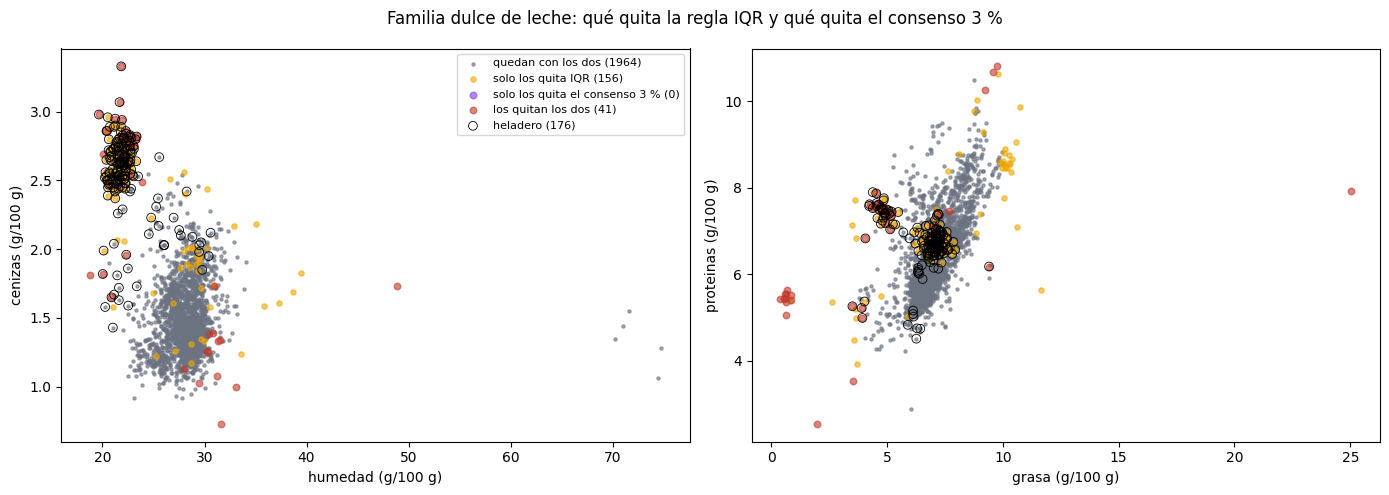

In [4]:
filas = {}
for n in list(esp.columns) + ["todo el DDL"]:
    sel = esp[n].to_numpy() if n in esp else (muestras["desc_familia"] == "dulce de leche").to_numpy()
    filas[n] = {"muestras": int(sel.sum())} | {f"conserva · {m}": int((sel & ~o).sum()) for m, o in quitar.items()}
especiales = pd.DataFrame(filas).T
display(especiales)

ddl = (muestras["desc_familia"] == "dulce de leche").to_numpy(); o2 = quitar[f"consenso {PCT_V2} %"]
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (x, y) in zip(ejes, [("humedad", "cenizas"), ("grasa", "proteinas")]):
    for sel, color, rot, s in [(ddl & ~out_iqr & ~o2, GRIS, "quedan con los dos", 5), (ddl & out_iqr & ~o2, AMBAR, "solo los quita IQR", 14),
                               (ddl & ~out_iqr & o2, VIOLETA, f"solo los quita el consenso {PCT_V2} %", 22), (ddl & out_iqr & o2, ROJO, "los quitan los dos", 22)]:
        ax.scatter(muestras.loc[sel, x], muestras.loc[sel, y], s=s, color=color, alpha=0.6, label=f"{rot} ({sel.sum()})")
    he = ddl & esp["heladero"].to_numpy()
    ax.scatter(muestras.loc[he, x], muestras.loc[he, y], s=40, facecolors="none", edgecolors="black", lw=0.6, label=f"heladero ({he.sum()})")
    ax.set_xlabel(f"{x} (g/100 g)"); ax.set_ylabel(f"{y} (g/100 g)")
ejes[0].legend(fontsize=8)
fig.suptitle(f"Familia dulce de leche: qué quita la regla IQR y qué quita el consenso {PCT_V2} %")
plt.tight_layout(); plt.show()

### 1.4 · Ejemplos: lo que quita solo uno de los dos
Con el corte en `PCT_V2` %. `votos` es cuántos de los tres métodos la marcan; `grupo_pre`, el grupo preliminar.

In [5]:
ver = ["Identificador", "desc_familia", "desc_producto", "subtipo_ref"] + COLUMNAS
tab = muestras[ver].assign(grupo_pre=pre, votos=cons[PCT_V2][1]["votos"].to_numpy())
solo_iqr = out_iqr & ~o2; solo_cons = o2 & ~out_iqr
print(f"Solo los quita IQR: {solo_iqr.sum()} · por familia:", muestras.loc[solo_iqr, "desc_familia"].value_counts().head(8).to_dict())
display(tab[solo_iqr].sample(min(10, solo_iqr.sum()), random_state=SEMILLA).sort_values("grupo_pre"))
print(f"Solo los quita el consenso {PCT_V2} %: {solo_cons.sum()} · por familia:", muestras.loc[solo_cons, "desc_familia"].value_counts().head(8).to_dict())
display(tab[solo_cons].sort_values("grupo_pre").head(12))
print("Los quitan los dos (los más claros):")
display(tab[out_iqr & o2].sort_values("votos", ascending=False).head(8))

Solo los quita IQR: 172 · por familia: {'dulce de leche': 156, 'suero / permeado': 8, 'yogur / bebida lactea': 7, 'concentrado proteico': 1}


,Identificador,desc_familia,desc_producto,subtipo_ref,humedad,grasa,proteinas,cenizas,grupo_pre,votos
1645,MQ-28215-01,dulce de leche,DULCE DE LECHE HELADERO,HELADERO,21.44,7.03,6.43,2.56,1,0
2181,MQ-36515-01,dulce de leche,DULCE DE LECHE FAMILIAR,FAMILIAR,28.65,2.63,5.36,1.31,1,0
2350,MQ-40377-01,dulce de leche,DULCE DE LECHE HELADERO,HELADERO,21.75,6.75,6.50,2.64,1,0
1335,MQ-23507-06,dulce de leche,DULCE DE LECHE REPOSTERO,REPOSTERO,25.00,10.59,7.10,1.68,1,1
2431,MQ-41703-01,dulce de leche,DULCE DE LECHE HELADERO,HELADERO,21.36,6.95,6.43,2.63,1,0
2539,MQ-43585-01,dulce de leche,DULCE DE LECHE HELADERO,HELADERO,20.96,7.70,6.61,2.51,1,0
1733,MQ-29482-01,dulce de leche,DULCE DE LECHE HELADERO SANTA,HELADERO,22.74,6.60,6.66,2.65,1,0
2238,MQ-37744-01,dulce de leche,DULCE DE LECHE HELADERO,HELADERO,20.54,7.26,6.80,2.45,1,0
1975,MQ-33114-01,dulce de leche,DULCE DE LECHE HELADERO,HELADERO,21.44,6.99,6.71,2.77,1,1
894,MQ-16356-01,dulce de leche,DULCE DE LECHE,NaN,28.54,10.27,8.77,1.87,1,0


Solo los quita el consenso 3 %: 6 · por familia: {'suero / permeado': 5, 'yogur / bebida lactea': 1}


,Identificador,desc_familia,desc_producto,subtipo_ref,humedad,grasa,proteinas,cenizas,grupo_pre,votos
78,MO-07984-01,yogur / bebida lactea,POLVO PARA PREPARAR BEBIDA LACTEA CON MALTODEX...,POLVO PARA PREPARAR,3.97,9.96,11.05,4.49,2,2
85,MO-08051-01,suero / permeado,PERMEADO DE SUERO EN POLVO,PERMEADO DE SUERO,1.79,0.00,2.14,5.23,2,2
177,MO-08765-01,suero / permeado,PERMEADO DE SUERO EN POLVO,PERMEADO DE SUERO,2.48,0.00,1.99,5.26,2,2
203,MO-08989-01,suero / permeado,PERMEADO DE SUERO EN POLVO,PERMEADO DE SUERO,1.70,0.00,1.84,4.77,2,2
366,MO-10248-01,suero / permeado,SUERO DE QUESO EN POLVO PARCIALMENTE DESMINERA...,DESMINERALIZADO,3.51,6.37,12.00,5.35,2,2
489,MO-11228-01,suero / permeado,PERMEADO DE SUERO EN POLVO,PERMEADO DE SUERO,1.73,0.00,1.88,4.87,2,2


Los quitan los dos (los más claros):


,Identificador,desc_familia,desc_producto,subtipo_ref,humedad,grasa,proteinas,cenizas,grupo_pre,votos
108,MO-08333-01,suero / permeado,SUERO DE QUESO · REENGRASADO CON OLEOMARGARINA...,REENGRASADO,1.49,55.17,4.86,3.98,0,3
145,MO-08545-04,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.36,1.03,13.62,0.84,1,3
142,MO-08545-01,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.39,0.97,14.25,0.90,1,3
143,MO-08545-02,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.28,0.91,14.07,0.84,1,3
144,MO-08545-03,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.30,1.06,13.94,0.78,1,3
150,MO-08633-01,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.24,1.05,13.74,0.83,1,3
146,MO-08545-05,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.29,1.01,13.92,0.81,1,3
151,MO-08633-02,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.22,0.91,13.52,0.82,1,3


### 1.5 · El k-medias final con cada filtro, y sus métricas
Con las muestras que quedan se reimputa, se reescala y se elige k por silueta (2 a 10), como el pipeline; los tags salen
de `etiquetar`. Cada variante se mide tres veces:

- **sobre sus propias muestras** (lo que reporta el pipeline): favorece al filtro que quita más, porque saca justo lo
  que está entre grupos;
- **sobre todas** las muestras (cada modelo las asigna con `predict`, en la escala común);
- **sobre las comunes**, las que ninguna variante quita: el mismo conjunto para todos, la comparación más justa.

La **silueta macro** promedia las medias de cada grupo (cada grupo pesa igual): el DDL, que es más de la mitad de las
muestras y está muy bien separado, deja de tapar a los grupos débiles. **Peor grupo** es la menor de esas medias.

In [6]:
comunes = ~np.logical_or.reduce(list(quitar.values()))
resultados, filas, et_todas = {}, {}, {}
for n, o in quitar.items():
    resultados[n], filas[n], et_todas[n] = M.variante(X, o, Z_todas, comunes)
    for e in esp.columns:
        filas[n][f"conserva {e}"] = int((esp[e].to_numpy() & ~o).sum())
comparacion = pd.DataFrame(filas).T.infer_objects()
r0 = resultados[f"consenso {PCT_V2} %"]
assert r0["K"] == ACTUAL[v]["k"] and set(r0["tags"].values()) == ACTUAL[v]["tags"] and len(r0["Z"]) == ACTUAL[v]["muestras"]
assert round(comparacion.loc[f"consenso {PCT_V2} %", "silueta global"], 3) == ACTUAL[v]["silueta"]
assert (r0["tag_de"] == actual.loc[~cons[PCT_V2][0], "tag"].to_numpy()).all(), "los tags actuales no se reproducen"
print(f"Actual (consenso {PCT_V2} %) reproducido: {len(r0['Z'])} muestras, k = {r0['K']}, silueta {comparacion.loc[f'consenso {PCT_V2} %', 'silueta global']:.3f}, mismos tags por muestra.")
print(f"Muestras comunes (no las quita ninguna variante): {comunes.sum()}")
display(comparacion.style.format(precision=3).format({"% quitado": "{:.1f}", "Calinski-Harabasz": "{:.0f}"}))
print("Silueta media por tag, en cada variante (sobre sus propias muestras):")
display(pd.concat({n: M.silueta_por_grupo(r["Z"], r["tag_de"])["silueta media"] for n, r in resultados.items()}, axis=1).round(3))
print("Muestras por tag:")
display(pd.concat({n: pd.Series(r["tag_de"]).value_counts() for n, r in resultados.items()}, axis=1).fillna(0).astype(int))

Actual (consenso 3 %) reproducido: 2597 muestras, k = 5, silueta 0.854, mismos tags por muestra.
Muestras comunes (no las quita ninguna variante): 2410


,% quitado,muestras,k,tags,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,silueta global (todas),silueta macro (todas),silueta global (comunes),silueta macro (comunes),Davies-Bouldin (comunes),conserva repostero,conserva heladero,conserva reducido en grasa
IQR (anterior),8.6,2431,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.869257,0.791109,0.615366,0.316797,9846,0.839349,0.747175,0.879491,0.801512,0.300508,616,36,0
consenso 2 %,1.4,2624,6,DDL LIQUIDO POLVO_GRASO POLVO_GRASO_2 POLVO_MAGRO PROT_ALTA,0.852310,0.792410,0.623895,0.294875,6628,0.841969,0.779028,0.879491,0.801512,0.300508,621,166,11
consenso 3 %,2.4,2597,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.853913,0.759912,0.620382,0.326592,7437,0.839349,0.747175,0.879491,0.801512,0.300508,620,152,3
consenso 5 %,4.1,2552,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.859340,0.770131,0.609685,0.323663,8900,0.839349,0.747175,0.879491,0.801512,0.300508,617,133,1


Silueta media por tag, en cada variante (sobre sus propias muestras):


,IQR (anterior),consenso 2 %,consenso 3 %,consenso 5 %
DDL,0.897,0.875,0.879,0.882
LIQUIDO,0.754,0.766,0.764,0.759
POLVO_GRASO,0.955,0.913,0.787,0.836
POLVO_MAGRO,0.734,0.745,0.749,0.765
PROT_ALTA,0.615,0.624,0.620,0.610
POLVO_GRASO_2,NaN,0.831,NaN,NaN


Muestras por tag:


,IQR (anterior),consenso 2 %,consenso 3 %,consenso 5 %
DDL,1960,2140,2116,2081
POLVO_MAGRO,341,337,335,328
POLVO_GRASO,71,4,87,84
PROT_ALTA,49,49,49,49
LIQUIDO,10,10,10,10
POLVO_GRASO_2,0,84,0,0


### 1.6 · Segundo nivel dentro de cada tag
Sobre el agrupamiento con el filtro por consenso en `PCT_V2` %, que conserva los DDL especiales (si se usara el de IQR,
casi no habría heladeros para encontrar). Dentro de cada tag con al menos 30 muestras se reescala y se prueban:

- **mezcla de gaussianas** con k por BIC entre 1 y 6 (`n_init = 3`, como la clase 46): si BIC elige 1, no hay estructura;
- **HDBSCAN** con `min_cluster_size` 20, 30, 40 y 50 (clase 43): cuántos grupos, cuánto ruido, y si es estable.

Contra el **subtipo conocido** (DDL: familiar/clásico, repostero, heladero; quesos: subtipo y, para los de familia queso
de Senasa, la clase de humedad del CAA, `cat_humedad` de `categorias_senasa.csv`; polvos: WPC, desmineralizado, suero...):
el **ARI** (Rand ajustado; 0 = azar, 1 = igual) sin el ruido y **con el ruido como un grupo más** (el honesto: no premia
mandar lo difícil al ruido), y la silueta y Davies-Bouldin dentro del tag, sin el ruido.

Se queda la partición de mayor ARI con el ruido. Cada subgrupo se describe con su centroide en g/100 g, su subtipo
mayoritario, la **pureza** (% del subgrupo que es de ese subtipo) y la **cobertura** (% de ese subtipo que cae en el
subgrupo). Regla para proponer un **subtag**: ARI >= 0,2; en el subgrupo, al menos 20 muestras con subtipo conocido y
que sean al menos la mitad del subgrupo; pureza >= 60 % y cobertura >= 50 %.
Si ningún subgrupo la cumple, no hay estructura que valga un subtag.

In [7]:
nombre_v2 = f"consenso {PCT_V2} %"
r2 = resultados[nombre_v2]
v2 = muestras[~quitar[nombre_v2]].reset_index(drop=True)
v2["cluster"] = r2["grupos"]; v2["tag"] = r2["tag_de"]
cat = pd.read_csv(R.TABLAS / f"categorias_{v}.csv", usecols=["Identificador", "familia", "cat_humedad"], encoding="utf-8-sig", low_memory=False)
v2["humedad_caa"] = v2["Identificador"].map(cat[cat["familia"] == "queso"].set_index("Identificador")["cat_humedad"])
v2["subtag"] = np.nan; v2["subtag"] = v2["subtag"].astype(object)
segundo, propuestas, sensibilidades = {}, {}, []
for tag in TAGS_SEGUNDO:
    sel = (v2["tag"] == tag).to_numpy()
    if sel.sum() < 30:
        print(f"{tag}: {sel.sum()} muestras, no se analiza."); continue
    sub = v2[sel].reset_index(drop=True); Xs = sub[COLUMNAS].to_numpy()
    refs = {"subtipo": sub["subtipo_ref"]}
    if tag == "QUESO":
        refs["humedad CAA"] = sub["humedad_caa"]
    print(f"\n━━━━━━━━ {tag}: {sel.sum()} muestras · con subtipo conocido {sub['subtipo_ref'].notna().sum()} · "
          f"subtipos: {sub['subtipo_ref'].value_counts().head(6).to_dict()}")
    for nref, ref in refs.items():
        sn = M.segundo_nivel(Xs, ref, tamanos=TAMANOS)
        if nref == "subtipo":
            print("BIC por cantidad de gaussianas (menor es mejor):", {k: round(b) for k, b in sn["bic"].items()}, "→ k =", sn["k_bic"])
        print(f"Contra {nref} ({ref.notna().sum()} conocidas):")
        display(sn["sensibilidad"].round(3))
        sensibilidades.append(sn["sensibilidad"].reset_index().assign(version=v, tag=tag, referencia=nref))
        particion, et = M.elegir_particion(sn)
        desc = M.describir_subgrupos(Xs, et, ref)
        ari = sn["sensibilidad"].loc[particion, "ARI con el ruido"]
        print(f"Partición elegida: {particion} (ARI con el ruido {ari:.3f}):"); display(desc)
        top = ref.value_counts().head(6).index
        display(pd.crosstab(pd.Series(np.where(et == -1, "ruido", et.astype(str)), name="subgrupo"), ref.where(ref.isin(top), "otro").fillna("sin dato").rename(nref)))
        prop = M.proponer_subtag(tag, desc, ari)
        print("Subtags propuestos:", prop if prop else "ninguno: no hay estructura que se corresponda con un subtipo real")
        segundo[(tag, nref)] = dict(sn=sn, particion=particion, desc=desc, ari=ari)
        if prop and not any(t == tag for t, _ in propuestas):      # la primera referencia que da subtags manda
            propuestas[(tag, nref)] = prop
            idx = np.flatnonzero(sel)
            ets = np.where(et == -1, "ruido", et.astype(str))
            for g, st in prop.items():
                v2.loc[idx[ets == g], "subtag"] = st
print("\nSubtags propuestos en", v, ":", {t: p for (t, _), p in propuestas.items()} or "ninguno")
print(v2["subtag"].value_counts().to_dict())


━━━━━━━━ DDL: 2116 muestras · con subtipo conocido 1521 · subtipos: {'FAMILIAR': 749, 'REPOSTERO': 620, 'HELADERO': 152}


BIC por cantidad de gaussianas (menor es mejor): {1: 20984, 2: 17873, 3: 16951, 4: 16403, 5: 16847, 6: 15803} → k = 6
Contra subtipo (1521 conocidas):


,grupos,ruido,silueta (sin ruido),silueta macro,Davies-Bouldin,ARI contra subtipo,ARI con el ruido,tamaños
partición,,,,,,,,
"GMM, k = 6 (BIC)",6,0,0.294,0.330,1.845,0.401,0.401,"[203, 166, 313, 121, 831, 482]"
HDBSCAN min_cluster_size 20,2,110,0.542,0.666,0.502,0.214,0.236,"[1898, 108]"
HDBSCAN min_cluster_size 30,2,117,0.543,0.671,0.496,0.213,0.239,"[1893, 106]"
HDBSCAN min_cluster_size 40,2,124,0.545,0.672,0.494,0.213,0.238,"[1886, 106]"
HDBSCAN min_cluster_size 50,2,122,0.545,0.672,0.494,0.213,0.239,"[1888, 106]"


Partición elegida: GMM, k = 6 (BIC) (ARI con el ruido 0.401):


,muestras,humedad,grasa,proteinas,cenizas,con subtipo,subtipo mayoritario,% pureza,% cobertura
subgrupo,,,,,,,,,
0,203,29.31,8.70,8.20,1.90,14,REPOSTERO,64.0,1.0
1,166,25.23,6.22,5.25,1.20,163,REPOSTERO,98.0,26.0
2,313,27.58,6.49,6.57,1.67,212,REPOSTERO,56.0,19.0
3,121,21.66,6.79,6.83,2.62,121,HELADERO,100.0,80.0
4,831,28.52,6.70,5.81,1.34,652,FAMILIAR,90.0,78.0
5,482,27.77,7.58,7.11,1.63,359,REPOSTERO,74.0,43.0


subtipo,FAMILIAR,HELADERO,REPOSTERO,otro
subgrupo,,,,
0,5,0,9,189
1,4,0,159,3
2,62,31,119,101
3,0,121,0,0
4,584,0,68,179
5,94,0,265,123


... (8 outputs left out)

Partición elegida: GMM, k = 6 (BIC) (ARI con el ruido 0.151):


,muestras,humedad,grasa,proteinas,cenizas,con subtipo,subtipo mayoritario,% pureza,% cobertura
subgrupo,,,,,,,,,
0,32,4.31,3.57,42.79,7.43,30,WPC,97.0,11.0
1,32,3.04,1.48,11.03,4.90,32,DESMINERALIZADO,47.0,100.0
2,39,3.90,0.81,35.46,7.35,10,WPC,100.0,4.0
3,89,3.88,3.70,35.18,5.21,89,WPC,100.0,33.0
4,124,4.06,3.00,35.86,6.16,124,WPC,100.0,46.0
5,19,4.67,3.54,35.77,5.08,19,WPC,100.0,7.0


subtipo,DESMINERALIZADO,PERMEADO DE SUERO,PROTEINAS LACTEAS,SUERO,WPC,otro
subgrupo,,,,,,
0,0,0,1,0,29,2
1,15,6,2,9,0,0
2,0,0,0,0,10,29
3,0,0,0,0,89,0
4,0,0,0,0,124,0
5,0,0,0,0,19,0


Subtags propuestos: ninguno: no hay estructura que se corresponda con un subtipo real

Subtags propuestos en senasa : {'DDL': {'3': 'DDL_HELADERO', '4': 'DDL_FAMILIAR'}}
{'DDL_FAMILIAR': 831, 'DDL_HELADERO': 121}


### 1.7 · Tabla comparativa y csv de prueba
La tabla de 1.5 más una fila para la versión 2 con los subtags (cada muestra con subtag cuenta como su propio grupo; las
demás, como su tag). Se guardan en `resultados/prueba_mejoras/`: `clusters_senasa_v2.csv` (una fila por muestra que
entra, con los dos filtros, los votos del consenso, el tag actual, y el cluster, tag, subtag y silueta de la versión 2),
`comparacion_senasa.csv` y `segundo_nivel_senasa.csv`.

In [8]:
etiqueta2 = v2["subtag"].fillna(v2["tag"]).to_numpy()
m2 = M.metricas(r2["Z"], etiqueta2)
fila = comparacion.loc[nombre_v2].copy()
fila.update({"k": m2["grupos"], "tags": " ".join(sorted(set(etiqueta2))), "silueta global": m2["silueta global"], "silueta macro": m2["silueta macro"],
             "peor grupo": m2["peor grupo"], "Davies-Bouldin": m2["Davies-Bouldin"], "Calinski-Harabasz": m2["Calinski-Harabasz"]})
for col in ["silueta global (todas)", "silueta macro (todas)", "silueta global (comunes)", "silueta macro (comunes)", "Davies-Bouldin (comunes)"]:
    fila[col] = np.nan
tabla = comparacion.copy(); tabla.loc[f"{nombre_v2} + subtags"] = fila
display(tabla.style.format(precision=3, na_rep="-").format({"% quitado": "{:.1f}", "Calinski-Harabasz": "{:.0f}"}))
v2["silueta"] = np.round(M.silhouette_samples(r2["Z"], r2["grupos"]), 4)
salida = muestras[["Identificador", "desc_familia", "origen"] + COLUMNAS].rename(columns={"desc_familia": "familia"})
salida["outlier_iqr"] = out_iqr; salida[f"outlier_consenso_{PCT_V2}"] = quitar[nombre_v2]; salida["votos_consenso"] = cons[PCT_V2][1]["votos"].to_numpy()
salida["tag_actual"] = actual["tag"].to_numpy()
salida = salida.merge(v2[["Identificador", "cluster", "tag", "subtag", "silueta"]], on="Identificador", how="left")
salida["cluster"] = salida["cluster"].astype("Int64")
salida.to_csv(PRUEBA / f"clusters_{v}_v2.csv", index=False, encoding="utf-8-sig")
tabla.rename_axis("variante").to_csv(PRUEBA / f"comparacion_{v}.csv", encoding="utf-8-sig")
pd.concat(sensibilidades).to_csv(PRUEBA / f"segundo_nivel_{v}.csv", index=False, encoding="utf-8-sig")
print(f"Guardado en {PRUEBA.relative_to(R.RAIZ)}: clusters_{v}_v2.csv ({len(salida)} filas, {int(salida['tag'].notna().sum())} con tag, "
      f"{int(salida['subtag'].notna().sum())} con subtag), comparacion_{v}.csv, segundo_nivel_{v}.csv")
RES[v] = dict(tabla=tabla, especiales=especiales, propuestas=propuestas, segundo=segundo)

,% quitado,muestras,k,tags,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,silueta global (todas),silueta macro (todas),silueta global (comunes),silueta macro (comunes),Davies-Bouldin (comunes),conserva repostero,conserva heladero,conserva reducido en grasa
IQR (anterior),8.6,2431,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.869257,0.791109,0.615366,0.316797,9846,0.839349,0.747175,0.879491,0.801512,0.300508,616,36,0
consenso 2 %,1.4,2624,6,DDL LIQUIDO POLVO_GRASO POLVO_GRASO_2 POLVO_MAGRO PROT_ALTA,0.852310,0.792410,0.623895,0.294875,6628,0.841969,0.779028,0.879491,0.801512,0.300508,621,166,11
consenso 3 %,2.4,2597,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.853913,0.759912,0.620382,0.326592,7437,0.839349,0.747175,0.879491,0.801512,0.300508,620,152,3
consenso 5 %,4.1,2552,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.859340,0.770131,0.609685,0.323663,8900,0.839349,0.747175,0.879491,0.801512,0.300508,617,133,1
consenso 3 % + subtags,2.4,2597,7,DDL DDL_FAMILIAR DDL_HELADERO LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.296419,0.578725,-0.123454,0.873788,5931,nan,nan,nan,nan,nan,620,152,3


Guardado en resultados\prueba_mejoras: clusters_senasa_v2.csv (2660 filas, 2597 con tag, 952 con subtag), comparacion_senasa.csv, segundo_nivel_senasa.csv

## 2 · Senasa + MQ
### 2.1 · Las muestras y la regla actual
`M.preparar` arma las mismas muestras que el notebook completo y les suma, **solo para comparar**, el subtipo conocido
(`desc_subtipo`; en dulce de leche sin subtipo, el de `desc_producto`; si no, el de `mq_tipo_muestra.csv`) y las marcas
de DDL especial (REPOSTERO, HELADERO, reducido en grasa / descremado / light, buscadas en `desc_producto`, `desc_subtipo`,
`desc_grasa`, `desc_atributos` y `Descripción`). Nada de eso entra en el agrupamiento. Se rehace la regla IQR, que era
la del notebook completo y ahora queda solo para comparar.

In [9]:
v = "senasa_mq"
muestras, S = M.preparar(True, S)
X = muestras[COLUMNAS].to_numpy()
Z_todas, _, _ = M.escalar(X)                       # escala común: todas las muestras antes de quitar outliers
esp = M.especiales_ddl(muestras)
actual = pd.read_csv(R.TABLAS / f"clusters_{v}.csv", encoding="utf-8-sig").set_index("Identificador").loc[muestras["Identificador"]]
out_iqr, pre, K_PRE = M.outliers_iqr(Z_todas)
print(f"{len(muestras)} muestras · k-medias preliminar con k = {K_PRE} · regla IQR (la anterior): {int(out_iqr.sum())} outliers "
      f"({100 * out_iqr.mean():.1f} %)")
print("Subtipo de referencia, por fuente:", muestras["fuente_subtipo"].fillna("sin subtipo").value_counts().to_dict())
print("DDL especiales:", esp.sum().to_dict())

3937 muestras · k-medias preliminar con k = 5 · regla IQR (la anterior): 362 outliers (9.2 %)
Subtipo de referencia, por fuente: {'Senasa': 2150, 'sin subtipo': 1462, 'mq_tipo_muestra': 319, 'Senasa (desc_producto)': 6}
DDL especiales: {'repostero': 623, 'heladero': 176, 'reducido en grasa': 11}


### 2.2 · Outliers por consenso dentro de cada grupo preliminar
Mismo punto de partida que la regla actual: el k-medias preliminar (k por silueta). Dentro de **cada grupo** se reescala
(media 0 y desvío 1 con las muestras del grupo, para que un grupo chico y compacto no quede aplastado por la escala
global) y se calculan los tres puntajes de la clase 46, donde más bajo es más raro: `negative_outlier_factor_` del factor
local (50 vecinos), `score_samples` del bosque de aislamiento (200 árboles) y `score_samples` de la elipse. Cada método
marca el p % de menor puntaje del grupo, y es outlier lo que marcan **al menos 2 de 3** (el consenso de la celda 31,
con voto en vez de rango promedio). Los grupos de menos de 30 muestras no se filtran.

La tabla cruzada dice cuánto coinciden con la regla IQR. Con el corte en 3 %, el consenso tiene que marcar exactamente los
mismos outliers que `resultados/tablas/clusters_senasa_mq.csv`: la celda lo verifica.

In [10]:
cons = {p: M.outliers_consenso(X, pre, pct=p) for p in PCTS}
assert (cons[PCT_V2][0] == actual["outlier"].to_numpy()).all(), f"el consenso {PCT_V2} % no reproduce los outliers de clusters_{v}.csv"
quitar = {"IQR (anterior)": out_iqr} | {f"consenso {p} %": cons[p][0] for p in PCTS}
display(pd.DataFrame({n: {"quitadas": int(o.sum()), "% quitado": round(100 * o.mean(), 1),
                          "también las quita IQR": int((o & out_iqr).sum()), "solo este método": int((o & ~out_iqr).sum()) if n != "IQR (anterior)" else 0}
                      for n, o in quitar.items()}).T)
print("% quitado por grupo preliminar:")
display(pd.DataFrame({n: pd.Series(o).groupby(pre).mean().mul(100).round(1) for n, o in quitar.items()})
        .assign(muestras=np.bincount(pre)).rename_axis("grupo preliminar"))
for p in PCTS:
    print(f"IQR contra consenso {p} %:"); display(pd.crosstab(pd.Series(out_iqr, name="IQR"), pd.Series(cons[p][0], name=f"consenso {p} %"), margins=True))
votos = cons[PCT_V2][1]
print(f"Con el corte en {PCT_V2} %, cuántas marca cada método y cuántas comparten (el consenso es >= 2):")
metodos = ["factor local", "bosque", "elipse"]
display(pd.DataFrame([[int((votos[a] & votos[b]).sum()) for b in metodos] for a in metodos], index=metodos, columns=metodos))

,quitadas,% quitado,también las quita IQR,solo este método
IQR (anterior),362.0,9.2,362.0,0.0
consenso 2 %,75.0,1.9,68.0,7.0
consenso 3 %,101.0,2.6,88.0,13.0
consenso 5 %,172.0,4.4,146.0,26.0


% quitado por grupo preliminar:


,IQR (anterior),consenso 2 %,consenso 3 %,consenso 5 %,muestras
grupo preliminar,,,,,
0,10.3,2.0,2.4,4.1,2281
1,12.9,2.0,3.2,5.3,665
2,0.0,1.5,1.5,1.5,67
3,8.2,1.5,2.6,4.3,466
4,0.9,2.0,2.6,4.8,458


IQR contra consenso 2 %:


consenso 2 %,False,True,All
IQR,,,
False,3568,7,3575
True,294,68,362
All,3862,75,3937


IQR contra consenso 3 %:


consenso 3 %,False,True,All
IQR,,,
False,3562,13,3575
True,274,88,362
All,3836,101,3937


IQR contra consenso 5 %:


consenso 5 %,False,True,All
IQR,,,
False,3549,26,3575
True,216,146,362
All,3765,172,3937


Con el corte en 3 %, cuántas marca cada método y cuántas comparten (el consenso es >= 2):


,factor local,bosque,elipse
factor local,119,76,80
bosque,76,119,73
elipse,80,73,119


### 2.3 · ¿Qué pasa con los dulces de leche especiales?
El repostero, el heladero y el reducido en grasa son DDL legítimos con composición propia (el heladero tiene menos
humedad y más cenizas). Una regla que mide distancia al centroide del DDL los ve lejos y los saca; un detector local
(LOF) o de densidad no tiene por qué. Cuántos **se conservan** con cada método:

,muestras,conserva · IQR (anterior),conserva · consenso 2 %,conserva · consenso 3 %,conserva · consenso 5 %
repostero,623,613,623,622,620
heladero,176,35,176,172,151
reducido en grasa,11,2,11,11,5
todo el DDL,2233,2044,2232,2225,2187


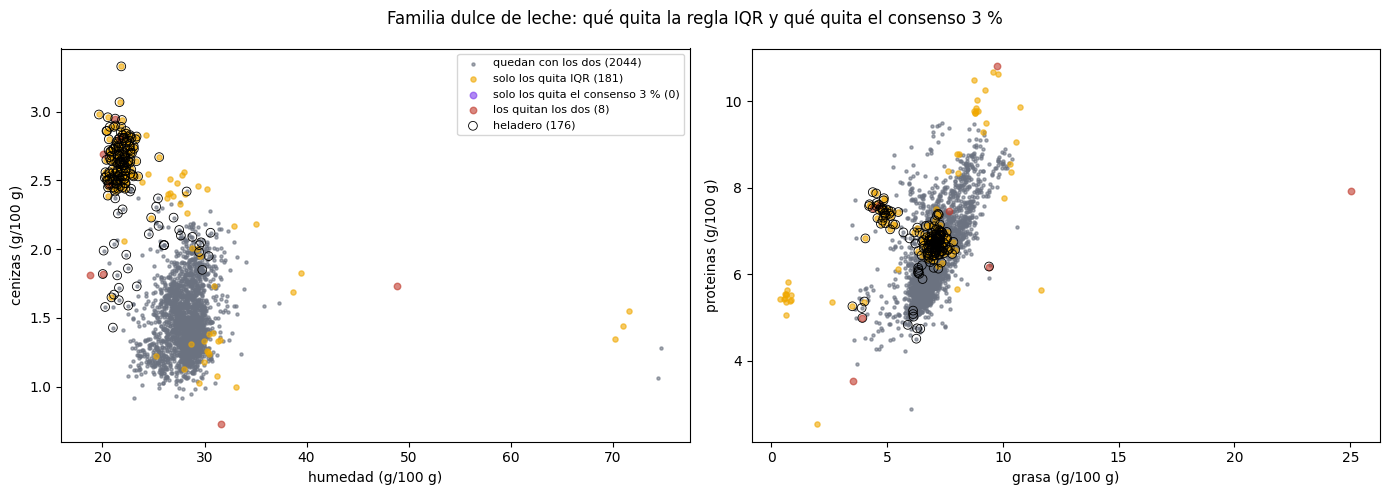

In [11]:
filas = {}
for n in list(esp.columns) + ["todo el DDL"]:
    sel = esp[n].to_numpy() if n in esp else (muestras["desc_familia"] == "dulce de leche").to_numpy()
    filas[n] = {"muestras": int(sel.sum())} | {f"conserva · {m}": int((sel & ~o).sum()) for m, o in quitar.items()}
especiales = pd.DataFrame(filas).T
display(especiales)

ddl = (muestras["desc_familia"] == "dulce de leche").to_numpy(); o2 = quitar[f"consenso {PCT_V2} %"]
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (x, y) in zip(ejes, [("humedad", "cenizas"), ("grasa", "proteinas")]):
    for sel, color, rot, s in [(ddl & ~out_iqr & ~o2, GRIS, "quedan con los dos", 5), (ddl & out_iqr & ~o2, AMBAR, "solo los quita IQR", 14),
                               (ddl & ~out_iqr & o2, VIOLETA, f"solo los quita el consenso {PCT_V2} %", 22), (ddl & out_iqr & o2, ROJO, "los quitan los dos", 22)]:
        ax.scatter(muestras.loc[sel, x], muestras.loc[sel, y], s=s, color=color, alpha=0.6, label=f"{rot} ({sel.sum()})")
    he = ddl & esp["heladero"].to_numpy()
    ax.scatter(muestras.loc[he, x], muestras.loc[he, y], s=40, facecolors="none", edgecolors="black", lw=0.6, label=f"heladero ({he.sum()})")
    ax.set_xlabel(f"{x} (g/100 g)"); ax.set_ylabel(f"{y} (g/100 g)")
ejes[0].legend(fontsize=8)
fig.suptitle(f"Familia dulce de leche: qué quita la regla IQR y qué quita el consenso {PCT_V2} %")
plt.tight_layout(); plt.show()

### 2.4 · Ejemplos: lo que quita solo uno de los dos
Con el corte en `PCT_V2` %. `votos` es cuántos de los tres métodos la marcan; `grupo_pre`, el grupo preliminar.

In [12]:
ver = ["Identificador", "desc_familia", "desc_producto", "subtipo_ref"] + COLUMNAS
tab = muestras[ver].assign(grupo_pre=pre, votos=cons[PCT_V2][1]["votos"].to_numpy())
solo_iqr = out_iqr & ~o2; solo_cons = o2 & ~out_iqr
print(f"Solo los quita IQR: {solo_iqr.sum()} · por familia:", muestras.loc[solo_iqr, "desc_familia"].value_counts().head(8).to_dict())
display(tab[solo_iqr].sample(min(10, solo_iqr.sum()), random_state=SEMILLA).sort_values("grupo_pre"))
print(f"Solo los quita el consenso {PCT_V2} %: {solo_cons.sum()} · por familia:", muestras.loc[solo_cons, "desc_familia"].value_counts().head(8).to_dict())
display(tab[solo_cons].sort_values("grupo_pre").head(12))
print("Los quitan los dos (los más claros):")
display(tab[out_iqr & o2].sort_values("votos", ascending=False).head(8))

Solo los quita IQR: 274 · por familia: {'dulce de leche': 181, 'leche en polvo': 28, 'queso': 19, 'sin clasificar': 18, 'suero / permeado': 13, 'yogur / bebida lactea': 7, 'leche fluida': 5, 'concentrado proteico': 2}


,Identificador,desc_familia,desc_producto,subtipo_ref,humedad,grasa,proteinas,cenizas,grupo_pre,votos
593,MQ-15136-02,dulce de leche,DULCE DE LECHE REPOSTERO · BALDE,REPOSTERO,26.91,8.93,9.78,2.39,0,0
2277,MQ-38903-01,dulce de leche,DULCE DE LECHE HELADERO,HELADERO,21.36,7.12,6.56,2.48,0,0
2673,MQ-43106-01,dulce de leche,DULCE DE LECHE HELADERO,HELADERO,20.44,7.55,6.82,2.50,0,0
1970,MQ-33034-01,dulce de leche,DULCE DE LECHE HELADERO,HELADERO,21.89,6.88,6.77,2.63,0,0
2906,MQ-44435-01,dulce de leche,DULCE DE LECHE FAMILIAR DESCREMADO,FAMILIAR,30.21,0.64,5.54,1.26,0,0
3747,MQ-45716-01,leche en polvo,NaN,NaN,3.13,25.45,27.95,5.90,1,0
3175,MQ-41258-01,sin clasificar,NaN,NaN,2.13,27.90,5.00,2.16,1,0
3656,MQ-45385-01,sin clasificar,NaN,NaN,2.56,28.20,13.29,5.08,1,0
3774,MQ-45795-08,leche fluida,NaN,CONCENTRADA,77.64,9.55,8.20,1.00,3,0
3388,MQ-43013-01,queso,NaN,NaN,75.37,7.97,7.61,1.70,3,0


Solo los quita el consenso 3 %: 13 · por familia: {'suero / permeado': 4, 'sin clasificar': 4, 'arroz con leche / postre': 3, 'concentrado proteico': 2}


,Identificador,desc_familia,desc_producto,subtipo_ref,humedad,grasa,proteinas,cenizas,grupo_pre,votos
2527,MQ-41840-01,concentrado proteico,CONCENTRADO DE PROTEINAS DE SUERO EN POLVO WPC,WPC,2.91,8.35,57.42,4.40,2,2
2838,MQ-43994-02,concentrado proteico,CONCENTRADO,NaN,97.89,0.02,0.29,1.82,3,2
3139,MQ-41004-01,arroz con leche / postre,NaN,NaN,70.07,1.09,3.00,0.84,3,2
3689,MQ-45484-01,arroz con leche / postre,NaN,ARROZ CON LECHE,68.91,3.29,3.51,0.60,3,2
3688,MQ-45483-01,arroz con leche / postre,NaN,ARROZ CON LECHE,71.31,3.10,3.39,0.53,3,2
3273,MQ-42059-01,sin clasificar,NaN,NaN,11.11,3.66,15.53,4.93,4,3
3089,MQ-40696-01,suero / permeado,NaN,SUERO,4.42,13.07,28.64,6.69,4,2
2377,MQ-40546-01,suero / permeado,SUERO DESMINERALIZADO EN POLVO,DESMINERALIZADO,2.07,8.37,15.22,5.20,4,2
3318,MQ-42360-01,suero / permeado,NaN,NaN,2.14,13.05,17.00,4.30,4,3
3310,MQ-42290-02,sin clasificar,NaN,NaN,13.60,1.81,21.13,7.03,4,3


Los quitan los dos (los más claros):


,Identificador,desc_familia,desc_producto,subtipo_ref,humedad,grasa,proteinas,cenizas,grupo_pre,votos
78,MO-07984-01,yogur / bebida lactea,POLVO PARA PREPARAR BEBIDA LACTEA CON MALTODEX...,POLVO PARA PREPARAR,3.97,9.96,11.05,4.49,0,3
85,MO-08051-01,suero / permeado,PERMEADO DE SUERO EN POLVO,PERMEADO DE SUERO,1.79,0.00,2.14,5.23,0,3
106,MO-08308-01,yogur / bebida lactea,POLVO PARA PREPARAR BEBIDA LACTEA CON MALTODEX...,POLVO PARA PREPARAR,3.46,11.23,11.33,4.39,0,3
142,MO-08545-01,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.39,0.97,14.25,0.90,0,3
143,MO-08545-02,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.28,0.91,14.07,0.84,0,3
144,MO-08545-03,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.30,1.06,13.94,0.78,0,3
145,MO-08545-04,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.36,1.03,13.62,0.84,0,3
146,MO-08545-05,suero / permeado,SUERO DESMINERALIZADO AL 90%,DESMINERALIZADO,2.29,1.01,13.92,0.81,0,3


### 2.5 · El k-medias final con cada filtro, y sus métricas
Con las muestras que quedan se reimputa, se reescala y se elige k por silueta (2 a 10), como el pipeline; los tags salen
de `etiquetar`. Cada variante se mide tres veces:

- **sobre sus propias muestras** (lo que reporta el pipeline): favorece al filtro que quita más, porque saca justo lo
  que está entre grupos;
- **sobre todas** las muestras (cada modelo las asigna con `predict`, en la escala común);
- **sobre las comunes**, las que ninguna variante quita: el mismo conjunto para todos, la comparación más justa.

La **silueta macro** promedia las medias de cada grupo (cada grupo pesa igual): el DDL, que es más de la mitad de las
muestras y está muy bien separado, deja de tapar a los grupos débiles. **Peor grupo** es la menor de esas medias.

In [13]:
comunes = ~np.logical_or.reduce(list(quitar.values()))
resultados, filas, et_todas = {}, {}, {}
for n, o in quitar.items():
    resultados[n], filas[n], et_todas[n] = M.variante(X, o, Z_todas, comunes)
    for e in esp.columns:
        filas[n][f"conserva {e}"] = int((esp[e].to_numpy() & ~o).sum())
comparacion = pd.DataFrame(filas).T.infer_objects()
r0 = resultados[f"consenso {PCT_V2} %"]
assert r0["K"] == ACTUAL[v]["k"] and set(r0["tags"].values()) == ACTUAL[v]["tags"] and len(r0["Z"]) == ACTUAL[v]["muestras"]
assert round(comparacion.loc[f"consenso {PCT_V2} %", "silueta global"], 3) == ACTUAL[v]["silueta"]
assert (r0["tag_de"] == actual.loc[~cons[PCT_V2][0], "tag"].to_numpy()).all(), "los tags actuales no se reproducen"
print(f"Actual (consenso {PCT_V2} %) reproducido: {len(r0['Z'])} muestras, k = {r0['K']}, silueta {comparacion.loc[f'consenso {PCT_V2} %', 'silueta global']:.3f}, mismos tags por muestra.")
print(f"Muestras comunes (no las quita ninguna variante): {comunes.sum()}")
display(comparacion.style.format(precision=3).format({"% quitado": "{:.1f}", "Calinski-Harabasz": "{:.0f}"}))
print("Silueta media por tag, en cada variante (sobre sus propias muestras):")
display(pd.concat({n: M.silueta_por_grupo(r["Z"], r["tag_de"])["silueta media"] for n, r in resultados.items()}, axis=1).round(3))
print("Muestras por tag:")
display(pd.concat({n: pd.Series(r["tag_de"]).value_counts() for n, r in resultados.items()}, axis=1).fillna(0).astype(int))

Actual (consenso 3 %) reproducido: 3836 muestras, k = 5, silueta 0.835, mismos tags por muestra.
Muestras comunes (no las quita ninguna variante): 3549


,% quitado,muestras,k,tags,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,silueta global (todas),silueta macro (todas),silueta global (comunes),silueta macro (comunes),Davies-Bouldin (comunes),conserva repostero,conserva heladero,conserva reducido en grasa
IQR (anterior),9.2,3575,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.861806,0.779391,0.584806,0.360833,23252,0.808864,0.731923,0.866549,0.786497,0.345524,613,35,2
consenso 2 %,1.9,3862,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.829440,0.748169,0.597929,0.376187,15788,0.808752,0.731566,0.866549,0.786497,0.345524,623,176,11
consenso 3 %,2.6,3836,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.834644,0.753618,0.596164,0.371020,17860,0.808770,0.731274,0.866549,0.786497,0.345524,622,172,11
consenso 5 %,4.4,3765,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.846476,0.765990,0.593488,0.360045,21332,0.808856,0.731405,0.866549,0.786497,0.345524,620,151,5


Silueta media por tag, en cada variante (sobre sus propias muestras):


,IQR (anterior),consenso 2 %,consenso 3 %,consenso 5 %
DDL,0.905,0.878,0.880,0.886
LIQUIDO,0.828,0.770,0.776,0.792
POLVO_GRASO,0.946,0.864,0.881,0.911
POLVO_MAGRO,0.632,0.630,0.635,0.646
PROT_ALTA,0.585,0.598,0.596,0.593


Muestras por tag:


,IQR (anterior),consenso 2 %,consenso 3 %,consenso 5 %
DDL,2047,2237,2226,2187
POLVO_GRASO,579,651,644,630
POLVO_MAGRO,454,449,446,436
LIQUIDO,428,459,454,446
PROT_ALTA,67,66,66,66


### 2.6 · Segundo nivel dentro de cada tag
Sobre el agrupamiento con el filtro por consenso en `PCT_V2` %, que conserva los DDL especiales (si se usara el de IQR,
casi no habría heladeros para encontrar). Dentro de cada tag con al menos 30 muestras se reescala y se prueban:

- **mezcla de gaussianas** con k por BIC entre 1 y 6 (`n_init = 3`, como la clase 46): si BIC elige 1, no hay estructura;
- **HDBSCAN** con `min_cluster_size` 20, 30, 40 y 50 (clase 43): cuántos grupos, cuánto ruido, y si es estable.

Contra el **subtipo conocido** (DDL: familiar/clásico, repostero, heladero; quesos: subtipo y, para los de familia queso
de Senasa, la clase de humedad del CAA, `cat_humedad` de `categorias_senasa_mq.csv`; polvos: WPC, desmineralizado, suero...):
el **ARI** (Rand ajustado; 0 = azar, 1 = igual) sin el ruido y **con el ruido como un grupo más** (el honesto: no premia
mandar lo difícil al ruido), y la silueta y Davies-Bouldin dentro del tag, sin el ruido.

Se queda la partición de mayor ARI con el ruido. Cada subgrupo se describe con su centroide en g/100 g, su subtipo
mayoritario, la **pureza** (% del subgrupo que es de ese subtipo) y la **cobertura** (% de ese subtipo que cae en el
subgrupo). Regla para proponer un **subtag**: ARI >= 0,2; en el subgrupo, al menos 20 muestras con subtipo conocido y
que sean al menos la mitad del subgrupo; pureza >= 60 % y cobertura >= 50 %.
Si ningún subgrupo la cumple, no hay estructura que valga un subtag.

In [14]:
nombre_v2 = f"consenso {PCT_V2} %"
r2 = resultados[nombre_v2]
v2 = muestras[~quitar[nombre_v2]].reset_index(drop=True)
v2["cluster"] = r2["grupos"]; v2["tag"] = r2["tag_de"]
cat = pd.read_csv(R.TABLAS / f"categorias_{v}.csv", usecols=["Identificador", "familia", "cat_humedad"], encoding="utf-8-sig", low_memory=False)
v2["humedad_caa"] = v2["Identificador"].map(cat[cat["familia"] == "queso"].set_index("Identificador")["cat_humedad"])
v2["subtag"] = np.nan; v2["subtag"] = v2["subtag"].astype(object)
segundo, propuestas, sensibilidades = {}, {}, []
for tag in TAGS_SEGUNDO:
    sel = (v2["tag"] == tag).to_numpy()
    if sel.sum() < 30:
        print(f"{tag}: {sel.sum()} muestras, no se analiza."); continue
    sub = v2[sel].reset_index(drop=True); Xs = sub[COLUMNAS].to_numpy()
    refs = {"subtipo": sub["subtipo_ref"]}
    if tag == "QUESO":
        refs["humedad CAA"] = sub["humedad_caa"]
    print(f"\n━━━━━━━━ {tag}: {sel.sum()} muestras · con subtipo conocido {sub['subtipo_ref'].notna().sum()} · "
          f"subtipos: {sub['subtipo_ref'].value_counts().head(6).to_dict()}")
    for nref, ref in refs.items():
        sn = M.segundo_nivel(Xs, ref, tamanos=TAMANOS)
        if nref == "subtipo":
            print("BIC por cantidad de gaussianas (menor es mejor):", {k: round(b) for k, b in sn["bic"].items()}, "→ k =", sn["k_bic"])
        print(f"Contra {nref} ({ref.notna().sum()} conocidas):")
        display(sn["sensibilidad"].round(3))
        sensibilidades.append(sn["sensibilidad"].reset_index().assign(version=v, tag=tag, referencia=nref))
        particion, et = M.elegir_particion(sn)
        desc = M.describir_subgrupos(Xs, et, ref)
        ari = sn["sensibilidad"].loc[particion, "ARI con el ruido"]
        print(f"Partición elegida: {particion} (ARI con el ruido {ari:.3f}):"); display(desc)
        top = ref.value_counts().head(6).index
        display(pd.crosstab(pd.Series(np.where(et == -1, "ruido", et.astype(str)), name="subgrupo"), ref.where(ref.isin(top), "otro").fillna("sin dato").rename(nref)))
        prop = M.proponer_subtag(tag, desc, ari)
        print("Subtags propuestos:", prop if prop else "ninguno: no hay estructura que se corresponda con un subtipo real")
        segundo[(tag, nref)] = dict(sn=sn, particion=particion, desc=desc, ari=ari)
        if prop and not any(t == tag for t, _ in propuestas):      # la primera referencia que da subtags manda
            propuestas[(tag, nref)] = prop
            idx = np.flatnonzero(sel)
            ets = np.where(et == -1, "ruido", et.astype(str))
            for g, st in prop.items():
                v2.loc[idx[ets == g], "subtag"] = st
print("\nSubtags propuestos en", v, ":", {t: p for (t, _), p in propuestas.items()} or "ninguno")
print(v2["subtag"].value_counts().to_dict())


━━━━━━━━ DDL: 2226 muestras · con subtipo conocido 1601 · subtipos: {'FAMILIAR': 789, 'REPOSTERO': 637, 'HELADERO': 175}


BIC por cantidad de gaussianas (menor es mejor): {1: 22244, 2: 18549, 3: 17737, 4: 17641, 5: 16883, 6: 16427} → k = 6
Contra subtipo (1601 conocidas):


,grupos,ruido,silueta (sin ruido),silueta macro,Davies-Bouldin,ARI contra subtipo,ARI con el ruido,tamaños
partición,,,,,,,,
"GMM, k = 6 (BIC)",6,0,0.318,0.313,1.653,0.408,0.408,"[230, 562, 172, 864, 258, 140]"
HDBSCAN min_cluster_size 20,3,122,0.541,0.651,0.457,0.228,0.241,"[1976, 104, 24]"
HDBSCAN min_cluster_size 30,2,122,0.557,0.631,0.574,0.242,0.248,"[1968, 136]"
HDBSCAN min_cluster_size 40,2,154,0.553,0.668,0.497,0.215,0.243,"[1959, 113]"
HDBSCAN min_cluster_size 50,2,155,0.553,0.672,0.491,0.212,0.242,"[1960, 111]"


Partición elegida: GMM, k = 6 (BIC) (ARI con el ruido 0.408):


,muestras,humedad,grasa,proteinas,cenizas,con subtipo,subtipo mayoritario,% pureza,% cobertura
subgrupo,,,,,,,,,
0,230,26.99,5.78,5.84,1.57,179,REPOSTERO,46.0,13.0
1,562,27.85,7.49,7.14,1.63,396,REPOSTERO,74.0,46.0
2,172,25.26,6.22,5.25,1.20,168,REPOSTERO,97.0,26.0
3,864,28.55,6.68,5.82,1.34,684,FAMILIAR,89.0,77.0
4,258,29.41,8.53,8.33,1.94,34,REPOSTERO,71.0,4.0
5,140,21.74,6.58,6.90,2.65,140,HELADERO,100.0,80.0


subtipo,FAMILIAR,HELADERO,REPOSTERO,otro
subgrupo,,,,
0,61,35,83,51
1,103,0,293,166
2,5,0,163,4
3,610,0,74,180
4,10,0,24,224
5,0,140,0,0


... (9 outputs left out)

Partición elegida: HDBSCAN min_cluster_size 30 (ARI con el ruido 0.603):


,muestras,humedad,grasa,proteinas,cenizas,con subtipo,subtipo mayoritario,% pureza,% cobertura
subgrupo,,,,,,,,,
0,59,2.60,1.72,13.09,4.88,59,DESMINERALIZADO,83.0,92.0
1,236,4.02,3.34,35.59,5.74,236,WPC,100.0,83.0
2,71,3.69,1.09,34.35,7.76,0,-,NaN,NaN
ruido,80,4.36,4.68,35.26,6.69,71,WPC,68.0,17.0


subtipo,DESMINERALIZADO,PROTEINAS LACTEAS,SUERO,WPC,otro
subgrupo,,,,,
0,49,1,9,0,0
1,0,0,0,236,0
2,0,0,0,0,71
ruido,4,2,17,48,9


Subtags propuestos: {'0': 'POLVO_MAGRO_DESMINERALIZADO', '1': 'POLVO_MAGRO_WPC'}

Subtags propuestos en senasa_mq : {'DDL': {'3': 'DDL_FAMILIAR', '5': 'DDL_HELADERO'}, 'POLVO_MAGRO': {'0': 'POLVO_MAGRO_DESMINERALIZADO', '1': 'POLVO_MAGRO_WPC'}}
{'DDL_FAMILIAR': 864, 'POLVO_MAGRO_WPC': 236, 'DDL_HELADERO': 140, 'POLVO_MAGRO_DESMINERALIZADO': 59}


### 2.7 · Tabla comparativa y csv de prueba
La tabla de 2.5 más una fila para la versión 2 con los subtags (cada muestra con subtag cuenta como su propio grupo; las
demás, como su tag). Se guardan en `resultados/prueba_mejoras/`: `clusters_senasa_mq_v2.csv` (una fila por muestra que
entra, con los dos filtros, los votos del consenso, el tag actual, y el cluster, tag, subtag y silueta de la versión 2),
`comparacion_senasa_mq.csv` y `segundo_nivel_senasa_mq.csv`.

In [15]:
etiqueta2 = v2["subtag"].fillna(v2["tag"]).to_numpy()
m2 = M.metricas(r2["Z"], etiqueta2)
fila = comparacion.loc[nombre_v2].copy()
fila.update({"k": m2["grupos"], "tags": " ".join(sorted(set(etiqueta2))), "silueta global": m2["silueta global"], "silueta macro": m2["silueta macro"],
             "peor grupo": m2["peor grupo"], "Davies-Bouldin": m2["Davies-Bouldin"], "Calinski-Harabasz": m2["Calinski-Harabasz"]})
for col in ["silueta global (todas)", "silueta macro (todas)", "silueta global (comunes)", "silueta macro (comunes)", "Davies-Bouldin (comunes)"]:
    fila[col] = np.nan
tabla = comparacion.copy(); tabla.loc[f"{nombre_v2} + subtags"] = fila
display(tabla.style.format(precision=3, na_rep="-").format({"% quitado": "{:.1f}", "Calinski-Harabasz": "{:.0f}"}))
v2["silueta"] = np.round(M.silhouette_samples(r2["Z"], r2["grupos"]), 4)
salida = muestras[["Identificador", "desc_familia", "origen"] + COLUMNAS].rename(columns={"desc_familia": "familia"})
salida["outlier_iqr"] = out_iqr; salida[f"outlier_consenso_{PCT_V2}"] = quitar[nombre_v2]; salida["votos_consenso"] = cons[PCT_V2][1]["votos"].to_numpy()
salida["tag_actual"] = actual["tag"].to_numpy()
salida = salida.merge(v2[["Identificador", "cluster", "tag", "subtag", "silueta"]], on="Identificador", how="left")
salida["cluster"] = salida["cluster"].astype("Int64")
salida.to_csv(PRUEBA / f"clusters_{v}_v2.csv", index=False, encoding="utf-8-sig")
tabla.rename_axis("variante").to_csv(PRUEBA / f"comparacion_{v}.csv", encoding="utf-8-sig")
pd.concat(sensibilidades).to_csv(PRUEBA / f"segundo_nivel_{v}.csv", index=False, encoding="utf-8-sig")
print(f"Guardado en {PRUEBA.relative_to(R.RAIZ)}: clusters_{v}_v2.csv ({len(salida)} filas, {int(salida['tag'].notna().sum())} con tag, "
      f"{int(salida['subtag'].notna().sum())} con subtag), comparacion_{v}.csv, segundo_nivel_{v}.csv")
RES[v] = dict(tabla=tabla, especiales=especiales, propuestas=propuestas, segundo=segundo)

,% quitado,muestras,k,tags,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,silueta global (todas),silueta macro (todas),silueta global (comunes),silueta macro (comunes),Davies-Bouldin (comunes),conserva repostero,conserva heladero,conserva reducido en grasa
IQR (anterior),9.2,3575,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.861806,0.779391,0.584806,0.360833,23252,0.808864,0.731923,0.866549,0.786497,0.345524,613,35,2
consenso 2 %,1.9,3862,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.829440,0.748169,0.597929,0.376187,15788,0.808752,0.731566,0.866549,0.786497,0.345524,623,176,11
consenso 3 %,2.6,3836,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.834644,0.753618,0.596164,0.371020,17860,0.808770,0.731274,0.866549,0.786497,0.345524,622,172,11
consenso 5 %,4.4,3765,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.846476,0.765990,0.593488,0.360045,21332,0.808856,0.731405,0.866549,0.786497,0.345524,620,151,5
consenso 3 % + subtags,2.6,3836,9,DDL DDL_FAMILIAR DDL_HELADERO LIQUIDO POLVO_GRASO POLVO_MAGRO POLVO_MAGRO_DESMINERALIZADO POLVO_MAGRO_WPC PROT_ALTA,0.437519,0.560147,-0.095204,0.880869,13717,nan,nan,nan,nan,nan,622,172,11


Guardado en resultados\prueba_mejoras: clusters_senasa_mq_v2.csv (3937 filas, 3836 con tag, 1299 con subtag), comparacion_senasa_mq.csv, segundo_nivel_senasa_mq.csv


## 3 · Las dos versiones juntas

In [16]:
cols = ["% quitado", "muestras", "k", "conserva repostero", "conserva heladero", "conserva reducido en grasa", "silueta global", "silueta macro", "peor grupo",
        "Davies-Bouldin", "Calinski-Harabasz", "silueta global (comunes)", "silueta macro (comunes)", "Davies-Bouldin (comunes)"]
juntas = pd.concat({v: RES[v]["tabla"][cols] for v in RES}, names=["versión", "variante"])
display(juntas.style.format(precision=3, na_rep="-").format({"% quitado": "{:.1f}", "Calinski-Harabasz": "{:.0f}"}))
filas = []
for v in RES:
    for (tag, ref), s in RES[v]["segundo"].items():
        filas.append({"versión": v, "tag": tag, "referencia": ref, "BIC elige k": s["sn"]["k_bic"], "partición elegida": s["particion"],
                      "ARI con el ruido": round(s["ari"], 3), "subtags": ", ".join(RES[v]["propuestas"].get((tag, ref), {}).values())})
display(pd.DataFrame(filas).set_index(["versión", "tag", "referencia"]))

BIC elige k            partición elegida  ARI con el ruido                                       subtags
versión   tag         referencia                                                                                                          
senasa    DDL         subtipo               6             GMM, k = 6 (BIC)             0.401                    DDL_HELADERO, DDL_FAMILIAR
          POLVO_GRASO subtipo               5             GMM, k = 5 (BIC)             0.698                                              
          POLVO_MAGRO subtipo               6             GMM, k = 6 (BIC)             0.151                                              
senasa_mq DDL         subtipo               6             GMM, k = 6 (BIC)             0.408                    DDL_FAMILIAR, DDL_HELADERO
          POLVO_GRASO subtipo               6             GMM, k = 6 (BIC)             0.882                                              
          POLVO_MAGRO subtipo               6  HDBSCAN min_cluster_size 30             0.603  POLVO_MAGRO_DESMINERALIZADO, POLVO_MAGRO_WPC

## 4 · Veredicto
Números de la ejecución con semilla 42 (tablas de las secciones 1.7, 2.7 y 3). Si se cambian los datos o las
correcciones, hay que volver a leerlos.

### Conviene sumar al notebook completo

**1 · Outliers por consenso, con corte en 3 %, en lugar de la regla IQR.** Se calcula dentro de cada grupo del k-medias
preliminar, reescalando dentro del grupo. Los parámetros son `M.outliers_consenso(X, grupos_preliminares, pct=3,
minimo=2, n_vecinos=50, tam_min=30)`: LOF con 50 vecinos, IsolationForest con 200 árboles y EllipticEnvelope, y es
outlier lo que marcan al menos 2 de 3.

| | solo Senasa: IQR | solo Senasa: consenso 3 % | Senasa + MQ: IQR | Senasa + MQ: consenso 3 % |
|---|---|---|---|---|
| % quitado | 8,6 | 2,4 | 9,2 | 2,6 |
| DDL heladero que se conservan (de 176) | 36 | 152 | 35 | 172 |
| DDL reducido en grasa que se conservan (de 11) | 0 | 3 | 2 | 11 |
| DDL repostero que se conservan (de 623) | 616 | 620 | 613 | 622 |
| k y tags | 5, los mismos | 5, los mismos | 5, los mismos | 5, los mismos |
| silueta global / macro (sus muestras) | 0,869 / 0,791 | 0,854 / 0,760 | 0,862 / 0,779 | 0,835 / 0,754 |
| silueta global / macro y DB (muestras comunes) | 0,879 / 0,802 / 0,301 | igual | 0,867 / 0,786 / 0,346 | igual |

- **La regla IQR saca casi todos los heladeros.** El heladero tiene una composición propia (humedad ~22 g/100 g y
  cenizas ~2,6, contra ~28,5 y ~1,3 del familiar) y la regla lo ve lejos del centroide del DDL. El consenso los conserva.
- Sobre las muestras que ninguna variante quita, **los cuatro filtros dan lo mismo**: misma silueta global y macro,
  y mismo Davies-Bouldin. La silueta más baja «sobre sus muestras» no indica un modelo peor. Es el costo de conservar
  muestras legítimas que están en el borde del grupo. Por eso la comparación justa es la de las muestras comunes.
- El 90 % (Senasa, 57 de 63) y el 87 % (Senasa + MQ, 88 de 101) de lo que quita el consenso también lo quita la regla IQR.
  Lo que quita solo el consenso (6 y 13 muestras) no incluye ningún dulce de leche. En Senasa son polvos raros dentro de su
  grupo: 4 permeados de suero, un suero parcialmente desmineralizado y un polvo para bebida láctea. En MQ son 4 sueros, 4
  sin clasificar, 3 arroces con leche y 2 concentrados (uno de ellos con 98 % de humedad, casi agua).
- Con el corte en 3 %, k y tags son los mismos con el consenso y con IQR, en las dos versiones. Con **2 %** se conserva
  algo más: en solo Senasa, 166 heladeros y los 11 reducidos en grasa (contra 152 y 3 con 3 %); en Senasa + MQ, 176 y 11
  (contra 172 y 11). Pero en solo Senasa el 2 % cambia el agrupamiento (k = 6: parte POLVO_GRASO en 4 y 84 muestras, y aparece
  el tag POLVO_GRASO_2). Con **5 %** se vuelven a perder heladeros (quedan 133 y 151). Se deja el 3 %, el corte que ya usa el
  notebook completo; el 2 % es la alternativa que quita menos (1,4 y 1,9 %).

**2 · Métricas sin sesgo de desbalance.** Conviene reportar siempre, junto a la silueta global, la **silueta macro**, la del
**peor grupo**, Davies-Bouldin y Calinski-Harabasz (`M.metricas`). Para comparar filtros, conviene medir sobre las
**muestras comunes** (`M.variante`). La silueta del DDL (0,88–0,90) tapa a PROT_ALTA (0,59–0,62) y, en Senasa + MQ, a POLVO_MAGRO (0,63–0,65): con el consenso en 3 %, la silueta macro es 0,09
más baja que la global en solo Senasa y 0,08 en Senasa + MQ (QUESO ya no está en el k-medias: los quesos van a su rama).

**3 · Segundo nivel, solo en DDL: `DDL_HELADERO` y `DDL_FAMILIAR`.** Se arma con `M.segundo_nivel`: GaussianMixture con
k por BIC entre 1 y 6 y `n_init=3`, sobre el DDL reescalado y después del filtro por consenso. El ARI contra el subtipo
es 0,40 en solo Senasa y 0,41 con MQ.
- `DDL_HELADERO`: es 100 % heladero y reúne el 80 % de los heladeros. Su centroide es humedad 21,7, grasa 6,6–6,8,
  proteínas 6,8–6,9 y cenizas 2,6.
- `DDL_FAMILIAR`: es 89–90 % familiar/clásico y reúne el 77–78 % de los familiares. Su centroide es humedad 28,5, grasa 6,7,
  proteínas 5,8 y cenizas 1,3.
- El **repostero no tiene estructura propia**: se reparte en cuatro componentes grandes. La más pura (97–98 %) junta solo el
  26 % de los reposteros. No lleva subtag.

### Candidato, a confirmar antes de sumarlo

**`POLVO_MAGRO_WPC` y `POLVO_MAGRO_DESMINERALIZADO`**, solo en Senasa + MQ, con HDBSCAN y `min_cluster_size` = 30.
- WPC: pureza 100 % y cobertura 83 %, con humedad 4,0, grasa 3,3, proteínas 35,6 y cenizas 5,7.
- Desmineralizado: pureza 83 % y cobertura 92 %, con humedad 2,6, grasa 1,7, proteínas 13,1 y cenizas 4,9.
- El ARI con el ruido es 0,60, pero depende del parámetro: con `min_cluster_size` 20 cae a 0,19 (con 40 o 50 queda en 0,57).
- Queda un tercer grupo de 71 muestras de MQ sin subtipo, con proteínas 34 y cenizas 7,8, y 80 muestras como ruido.
- En solo Senasa no aparece: hay solo 15 desmineralizados y el ARI es 0,15.

### No conviene sumar

- **Consenso con 5 %**, por lo que se ve más arriba: pierde heladeros (133 y 151). El 2 % conserva algo más, pero se
  mantiene el 3 % del notebook completo.
- **HDBSCAN para el DDL**: deja un grupo gigante (casi el 90 % del DDL) y manda entre 110 y 155 muestras al ruido.
  El ARI con el ruido es ~0,24–0,25. La mezcla de gaussianas lo supera (0,40–0,41).
- **Subtags de QUESO**: ya no se analizan acá. Los quesos que confirma el catálogo salen del k-medias y van a una rama
  propia (humedad y materia grasa), con el subtag de la clase de humedad del CAA; el tag QUESO no aparece en el primer
  nivel de ninguna de las dos versiones. La prueba de ese agrupamiento es `prueba_clustering_quesos.ipynb`.
- **Subtags de POLVO_GRASO**: ningún subgrupo cumple la regla, en las dos versiones. En Senasa + MQ (644 muestras, 70 con
  subtipo conocido) el más grande (MODIFICADA, 239 muestras) llega a 96 % de pureza pero tiene subtipo conocido en solo el
  21 % de sus muestras (51), y los otros con subtipo son de 5 muestras (suero, pureza 60 %) y de 10 (polvo para preparar,
  100 %, con 7 con subtipo), demasiado chicos para un subtag. En solo Senasa el tag tiene 87 muestras (la leche en polvo y
  unos sueros reengrasados) y solo 17 con subtipo conocido: el único subgrupo puro (polvo para preparar, 7 muestras) no
  llega a las 20 que pide la regla, y el grupo grande (57 muestras) no tiene ningún subtipo conocido. HDBSCAN manda todo
  al ruido en las dos versiones.
- **Evaluar los subtags con la silueta global**: la fila «+ subtags» baja a 0,30 y 0,44, y el DDL residual (lo que
  queda sin subtag) da una silueta negativa. Es esperable, porque los subtags son un segundo nivel dentro del tag y no
  grupos del primer nivel. Se juzgan por ARI, pureza y cobertura.

### Dudas abiertas

- En DDL, en POLVO_MAGRO y en POLVO_GRASO de Senasa + MQ el BIC elige el máximo probado (k = 6; en POLVO_GRASO de solo
  Senasa elige 5). La mezcla
  de gaussianas aproxima una densidad continua: no prueba que haya seis tipos. Por eso los subtags se proponen solo para las componentes que coinciden con
  un subtipo real.
- El subtipo de referencia usa `mq_tipo_muestra.csv` en 319 muestras de Senasa + MQ (y 2 de solo Senasa). Una parte sale del clasificador de familias y no
  está revisada a mano.
- «Reducido en grasa» incluye DESCREMADO y LIGHT (11 DDL en total). Se buscó en `desc_producto`, `desc_subtipo`,
  `desc_grasa`, `desc_atributos` y `Descripción`.